In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"../../Dataset/NF-UNSW-NB15-v2.csv", low_memory=False)
df.head(5)

,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,...,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label,Attack
0,59.166.0.5,1305,149.171.126.8,21,6,1.0,9,1,193,3,...,0,7240,0,0,0,0,0,331.0,0,Benign
1,59.166.0.5,1305,149.171.126.8,21,6,1.0,261,5,469,7,...,8688,8688,18944,74,0,0,0,230.0,0,Benign
2,59.166.0.5,1305,149.171.126.8,21,6,1.0,481,9,750,11,...,10136,10136,33792,132,0,0,0,229.0,0,Benign
3,59.166.0.5,1305,149.171.126.8,21,6,1.0,701,13,1054,15,...,11584,11584,48640,190,0,0,0,125.0,0,Benign
4,59.166.0.5,1305,149.171.126.8,21,6,1.0,1031,19,1474,21,...,14480,13032,64256,251,0,0,0,230.0,0,Benign


In [3]:
df.shape

(2390275, 45)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2390275 entries, 0 to 2390274
Data columns (total 45 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   IPV4_SRC_ADDR                object 
 1   L4_SRC_PORT                  int64  
 2   IPV4_DST_ADDR                object 
 3   L4_DST_PORT                  int64  
 4   PROTOCOL                     int64  
 5   L7_PROTO                     float64
 6   IN_BYTES                     int64  
 7   IN_PKTS                      int64  
 8   OUT_BYTES                    int64  
 9   OUT_PKTS                     int64  
 10  TCP_FLAGS                    int64  
 11  CLIENT_TCP_FLAGS             int64  
 12  SERVER_TCP_FLAGS             int64  
 13  FLOW_DURATION_MILLISECONDS   int64  
 14  DURATION_IN                  int64  
 15  DURATION_OUT                 int64  
 16  MIN_TTL                      int64  
 17  MAX_TTL                      int64  
 18  LONGEST_FLOW_PKT             int64  
 19  

In [5]:
df.describe()

,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,...,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label
count,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,...,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06,2.390275e+06
mean,3.254961e+04,1.142309e+04,9.151913e+00,3.038721e+00,4.621664e+03,3.603686e+01,3.526565e+04,4.570363e+01,1.989969e+01,1.961149e+01,...,2.382468e+01,1.738763e+04,1.222160e+04,1.894443e+04,7.400138e+01,4.949701e+03,2.970099e+00,2.725637e+04,3.765351e+01,3.976655e-02
std,1.916212e+04,1.853915e+04,1.101865e+01,1.358876e+01,7.021409e+04,7.995682e+01,1.565155e+05,1.174495e+02,1.113381e+01,1.105082e+01,...,1.114788e+02,1.693017e+04,1.097592e+04,2.037120e+04,7.957477e+01,1.378088e+04,1.240340e+02,8.958054e+06,8.430295e+01,1.954103e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.583100e+04,2.500000e+01,6.000000e+00,0.000000e+00,4.810000e+02,4.000000e+00,3.120000e+02,4.000000e+00,1.900000e+01,1.900000e+01,...,0.000000e+00,0.000000e+00,5.792000e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,3.265000e+04,8.000000e+01,6.000000e+00,0.000000e+00,1.684000e+03,1.800000e+01,2.456000e+03,1.800000e+01,2.700000e+01,2.700000e+01,...,0.000000e+00,1.448000e+04,1.303200e+04,1.100800e+04,4.300000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,4.907600e+04,1.588700e+04,6.000000e+00,1.000000e+00,3.286000e+03,4.400000e+01,1.496800e+04,4.400000e+01,2.700000e+01,2.700000e+01,...,1.200000e+01,2.461600e+04,1.448000e+04,3.379200e+04,1.320000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,6.553500e+04,6.553500e+04,2.550000e+02,2.480000e+02,3.024141e+07,2.289400e+04,1.465852e+07,1.107800e+04,3.100000e+01,3.100000e+01,...,1.967600e+04,6.553300e+04,6.553100e+04,6.531700e+04,2.550000e+02,6.553500e+04,5.593700e+04,4.283358e+09,5.010000e+02,1.000000e+00


In [6]:
df.isnull().sum()

IPV4_SRC_ADDR                  0
L4_SRC_PORT                    0
IPV4_DST_ADDR                  0
L4_DST_PORT                    0
PROTOCOL                       0
L7_PROTO                       0
IN_BYTES                       0
IN_PKTS                        0
OUT_BYTES                      0
OUT_PKTS                       0
TCP_FLAGS                      0
CLIENT_TCP_FLAGS               0
SERVER_TCP_FLAGS               0
FLOW_DURATION_MILLISECONDS     0
DURATION_IN                    0
DURATION_OUT                   0
MIN_TTL                        0
MAX_TTL                        0
LONGEST_FLOW_PKT               0
SHORTEST_FLOW_PKT              0
MIN_IP_PKT_LEN                 0
MAX_IP_PKT_LEN                 0
SRC_TO_DST_SECOND_BYTES        0
DST_TO_SRC_SECOND_BYTES        0
RETRANSMITTED_IN_BYTES         0
RETRANSMITTED_IN_PKTS          0
RETRANSMITTED_OUT_BYTES        0
RETRANSMITTED_OUT_PKTS         0
SRC_TO_DST_AVG_THROUGHPUT      0
DST_TO_SRC_AVG_THROUGHPUT      0
NUM_PKTS_U

df.duplicated().sum()

## display count

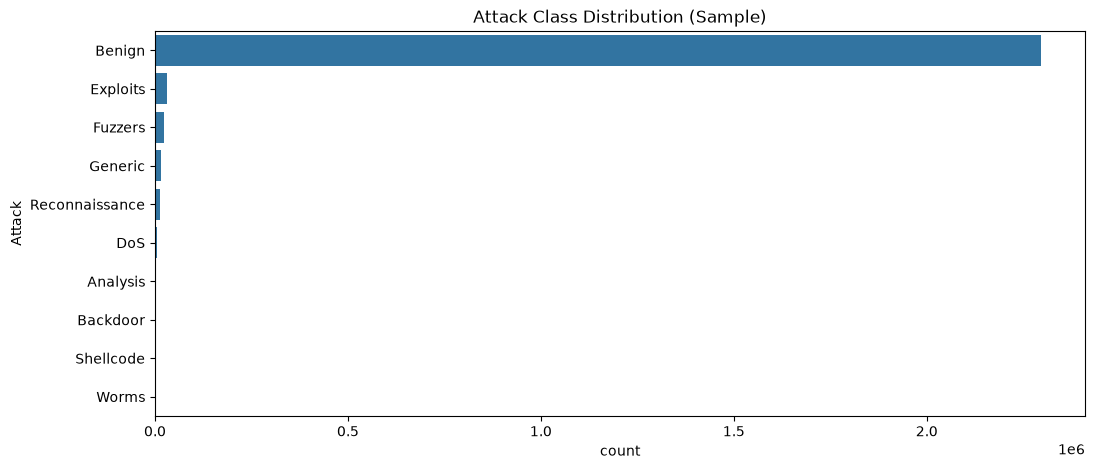

Attack
Benign            96.02
Exploits           1.32
Fuzzers            0.93
Generic            0.69
Reconnaissance     0.53
DoS                0.24
Analysis           0.10
Backdoor           0.09
Shellcode          0.06
Worms              0.01
Name: proportion, dtype: float64


In [7]:
plt.figure(figsize=(12,5))
order = df["Attack"].value_counts().index
sns.countplot(data=df, y="Attack", order=order)
plt.title("Attack Class Distribution (Sample)")
plt.show()

print(df["Attack"].value_counts(normalize=True).mul(100).round(2))

In [8]:

# 1. Downcast integers one column at a time (In-place)
for col in df.select_dtypes(include=['int64']).columns:
    df[col] = pd.to_numeric(df[col], downcast='integer')

# 2. Downcast floats one column at a time (In-place)
for col in df.select_dtypes(include=['float64']).columns:
    df[col] = pd.to_numeric(df[col], downcast='float')

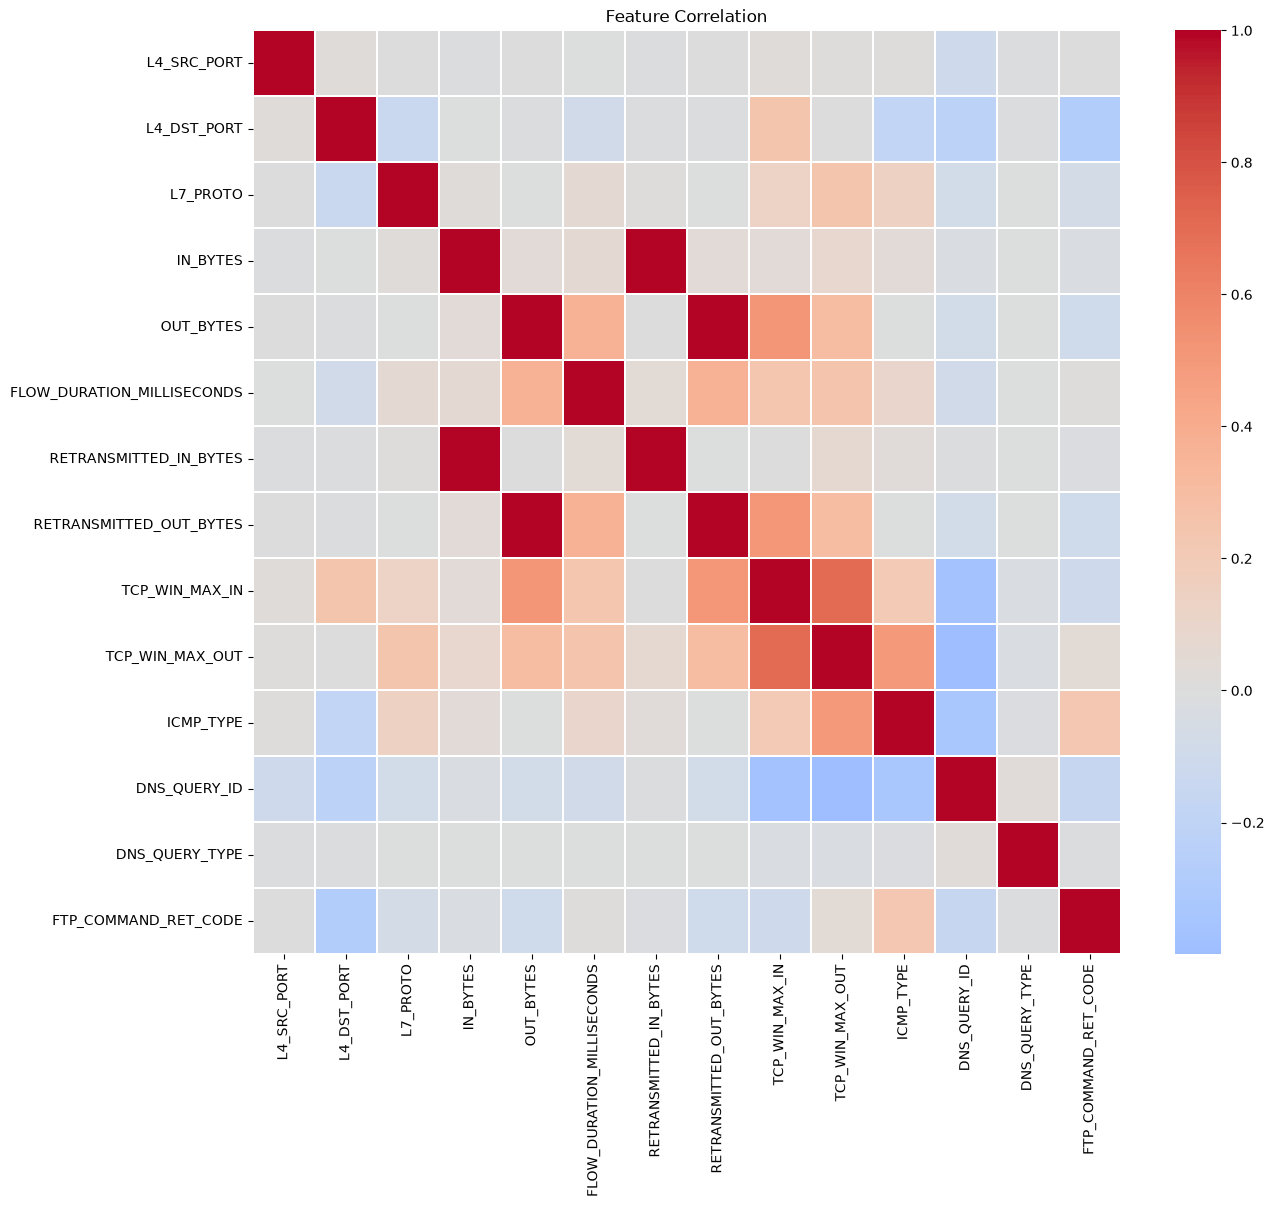

In [9]:
num_cols = df.select_dtypes(include=["int32","float32"]).columns.tolist()
# remove Label if present
corr = df[num_cols].corr()

plt.figure(figsize=(14,12))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Feature Correlation")
plt.show()

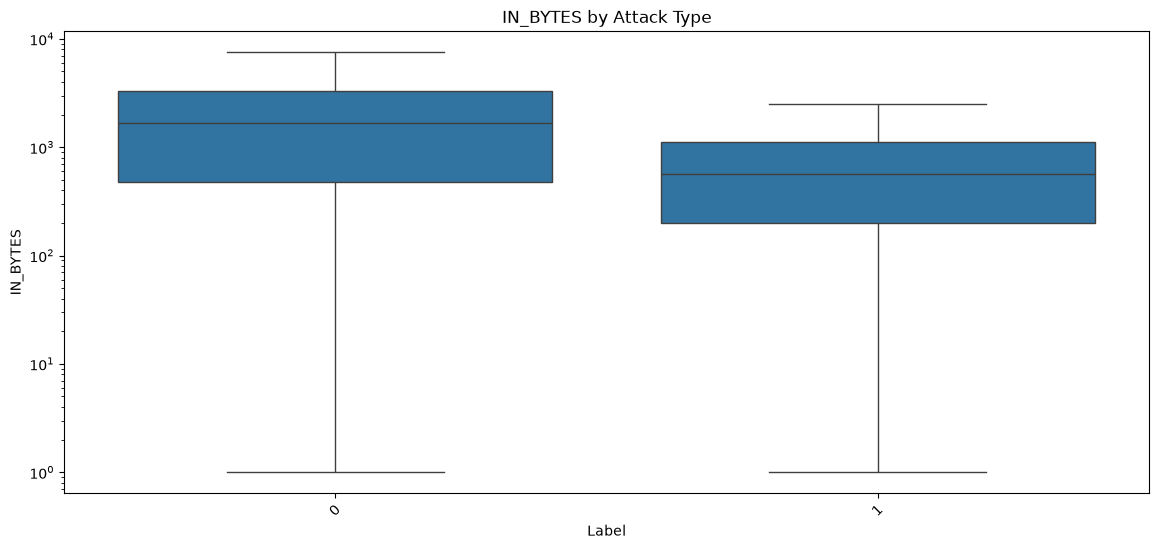

In [10]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df, x="Label", y="IN_BYTES", showfliers=False)
plt.xticks(rotation=45)
plt.yscale("log")
plt.title("IN_BYTES by Attack Type")
plt.show()

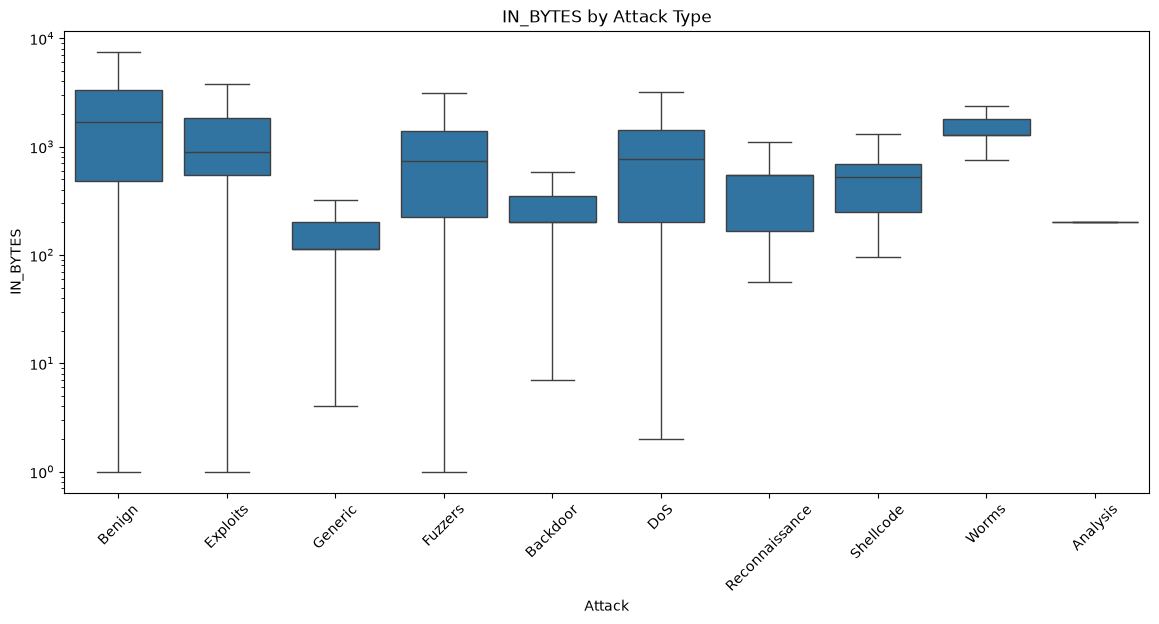

In [11]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df, x="Attack", y="IN_BYTES", showfliers=False)
plt.xticks(rotation=45)
plt.yscale("log")
plt.title("IN_BYTES by Attack Type")
plt.show()

### drop column

In [12]:
drop_cols = [
    'IPV4_SRC_ADDR', 'IPV4_DST_ADDR',
    'L4_SRC_PORT',
    'DNS_QUERY_ID'         # keep 'Label' as binary target
]
# Optionally also:
# drop_cols += ['L4_DST_PORT']          # if you don't bin it
# drop_cols += ['CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS']  # if corr with TCP_FLAGS > 0.95

df.drop(columns=drop_cols,inplace=True)
# y = df['Label']   # binary 0/1 target

In [13]:
df.shape

(2390275, 41)

## Drop column zero-varience

In [14]:
# 1. Near-zero-variance columns (e.g., a column that's 99.9% one value)
from sklearn.feature_selection import VarianceThreshold
near_zero = [c for c in df.columns if df[c].value_counts(normalize=True).iloc[0] > 0.999]

# 2. Highly correlated pairs (|r| > 0.95) — keep one
corr = df.select_dtypes('number').corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_drop = [c for c in upper.columns if any(upper[c] > 0.95)]

# 3. All-NaN or all-zero columns
all_zero_or_nan = [c for c in df.columns if (df[c].fillna(-1) == df[c].iloc[0]).all()]

In [15]:
# 1. Select only numeric columns (correlation requires numbers)
numeric_df = df.select_dtypes(include=['number'])

# 2. Calculate correlation of all numeric columns with 'Label'
# We drop 'Label' itself from the result to avoid a perfect 1.0 correlation
corr_with_label = numeric_df.corr()['Label'].drop('Label')

# 3. Sort by absolute value to see the strongest relationships first
sorted_corr = corr_with_label.abs().sort_values(ascending=False)

print("--- Correlation of Features with 'Label' ---")
print(sorted_corr)

--- Correlation of Features with 'Label' ---
MIN_TTL                        0.824906
MAX_TTL                        0.824857
MIN_IP_PKT_LEN                 0.484103
PROTOCOL                       0.280589
SHORTEST_FLOW_PKT              0.159197
SERVER_TCP_FLAGS               0.155205
TCP_FLAGS                      0.121476
CLIENT_TCP_FLAGS               0.117141
L4_DST_PORT                    0.107090
NUM_PKTS_UP_TO_128_BYTES       0.099058
TCP_WIN_MAX_IN                 0.092124
MAX_IP_PKT_LEN                 0.086539
LONGEST_FLOW_PKT               0.086539
DST_TO_SRC_AVG_THROUGHPUT      0.057337
DNS_QUERY_TYPE                 0.054415
OUT_PKTS                       0.050564
FTP_COMMAND_RET_CODE           0.044619
TCP_WIN_MAX_OUT                0.040457
RETRANSMITTED_OUT_PKTS         0.039813
DURATION_IN                    0.038765
FLOW_DURATION_MILLISECONDS     0.038436
IN_PKTS                        0.038428
RETRANSMITTED_IN_BYTES         0.034925
DURATION_OUT                   0.03

In [16]:
df.shape

(2390275, 41)

In [17]:
# Check if every single row matches perfectly
are_identical = df['MAX_IP_PKT_LEN'].equals(df['LONGEST_FLOW_PKT'])
print(f"Are the columns exact duplicates? {are_identical}")

# Alternatively, count how many rows are different
differences = (df['MAX_IP_PKT_LEN'] != df['LONGEST_FLOW_PKT']).sum()
print(f"Number of rows where they differ: {differences} out of {len(df)}")


Are the columns exact duplicates? True
Number of rows where they differ: 0 out of 2390275


In [18]:
# List of columns to drop based on redundancy and low correlation
cols_to_drop = [
    'LONGEST_FLOW_PKT',            # Redundant with MAX_IP_PKT_LEN
    'ICMP_TYPE',                   # Near-zero correlation
    'ICMP_IPV4_TYPE',              # Near-zero correlation
    'DST_TO_SRC_SECOND_BYTES',     # Near-zero correlation
    'SRC_TO_DST_SECOND_BYTES'      # Near-zero correlation
]

# Drop the columns from your DataFrame (replace 'df' with your variable name)
df.drop(columns=cols_to_drop, inplace=True, errors='ignore')


## Skewness check

In [19]:
# 1. Isolate numeric columns
numeric_cols = df.select_dtypes(include=['number']).columns

# 2. Calculate skewness (Pandas handles this efficiently even on large datasets)
skewness_values = df[numeric_cols].skew().sort_values(ascending=False)

# 3. Display as a clean DataFrame
skew_df = pd.DataFrame({'Column': skewness_values.index, 'Skewness': skewness_values.values})
print("--- Skewness of All Numeric Columns ---")
print(skew_df.to_string(index=False))

--- Skewness of All Numeric Columns ---
                     Column   Skewness
             DNS_TTL_ANSWER 369.837869
             DNS_QUERY_TYPE 274.694910
     RETRANSMITTED_IN_BYTES 259.768642
                   IN_BYTES 259.039324
      RETRANSMITTED_IN_PKTS 233.567566
  NUM_PKTS_256_TO_512_BYTES 217.507449
                    IN_PKTS  75.942572
                DURATION_IN  31.090211
NUM_PKTS_1024_TO_1514_BYTES  26.702091
               DURATION_OUT  25.802879
          SHORTEST_FLOW_PKT  23.424087
  SRC_TO_DST_AVG_THROUGHPUT  16.918234
                   PROTOCOL  13.531138
     RETRANSMITTED_OUT_PKTS  13.097212
    RETRANSMITTED_OUT_BYTES  12.160321
                  OUT_BYTES  12.119828
  NUM_PKTS_128_TO_256_BYTES  11.862865
                   OUT_PKTS  11.558621
 NUM_PKTS_512_TO_1024_BYTES  11.545945
  DST_TO_SRC_AVG_THROUGHPUT   8.769573
                   L7_PROTO   6.458734
   NUM_PKTS_UP_TO_128_BYTES   5.228700
                    MIN_TTL   4.996356
                    MAX_

In [20]:
from sklearn.preprocessing import RobustScaler

# Select numeric columns except the target column
numeric_cols = df.select_dtypes(include=np.number).columns.drop(
    "Label", errors="ignore"
)

# Log transformation: requires non-negative values
if (df[numeric_cols] < 0).any().any():
    raise ValueError("Negative values found. log1p cannot be applied safely.")

df[numeric_cols] = np.log1p(df[numeric_cols])

# Robust scaling
scaler = RobustScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

print("Transformation and RobustScaler applied successfully.")
print(df.head())

Transformation and RobustScaler applied successfully.
   L4_DST_PORT  PROTOCOL  L7_PROTO  IN_BYTES   IN_PKTS  OUT_BYTES  OUT_PKTS  \
0    -0.203174       0.0       1.0 -2.670576 -1.024607  -0.656449 -0.709142   
1    -0.203174       0.0       1.0 -0.969471 -0.524607  -0.427653 -0.393677   
2    -0.203174       0.0       1.0 -0.651935 -0.292120  -0.306472 -0.209142   
3    -0.203174       0.0       1.0 -0.456086 -0.138985  -0.218589 -0.078212   
4    -0.203174       0.0       1.0 -0.255376  0.023345  -0.131940  0.066722   

   TCP_FLAGS  CLIENT_TCP_FLAGS  SERVER_TCP_FLAGS  ...  \
0  -0.337209         -0.337209         -1.000000  ...   
1  -0.337209         -0.337209         -0.227451  ...   
2  -0.337209         -0.337209         -0.227451  ...   
3  -0.337209         -0.337209         -0.227451  ...   
4  -0.337209         -0.337209         -0.227451  ...   

   NUM_PKTS_256_TO_512_BYTES  NUM_PKTS_512_TO_1024_BYTES  \
0                        0.0                         0.0   
1       

In [21]:
# Count occurrences of 0 and 1 in Label
print(df["Label"].value_counts().reindex([0, 1], fill_value=0))

# Count and percentage
print("\nLabel distribution:")
print(df["Label"].value_counts(normalize=False).reindex([0, 1], fill_value=0))

print("\nPercentage distribution:")
print(
    (df["Label"].value_counts(normalize=True) * 100)
    .reindex([0, 1], fill_value=0)
    .round(2)
)

Label
0    2295222
1      95053
Name: count, dtype: int64

Label distribution:
Label
0    2295222
1      95053
Name: count, dtype: int64

Percentage distribution:
Label
0    96.02
1     3.98
Name: proportion, dtype: float64


In [22]:
np.isinf(df.select_dtypes(include=[np.number])).values.sum()

np.int64(0)

In [23]:
# If you still have the raw df with string Attack labels:
counts = df['Attack'].value_counts()
print(counts)

Attack
Benign            2295222
Exploits            31551
Fuzzers             22310
Generic             16560
Reconnaissance      12779
DoS                  5794
Analysis             2299
Backdoor             2169
Shellcode            1427
Worms                 164
Name: count, dtype: int64


In [24]:
df.shape

(2390275, 36)

In [25]:
df.drop(columns=['Label'], inplace=True)

In [26]:

import pandas as pd
import numpy as np

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

# ============================================================
# STEP 1: Separate features and target
# ============================================================

target_col = "Attack"

if target_col not in df.columns:
    raise ValueError("The 'Attack' column is missing.")

# Exclude Label to prevent binary target leakage
had_label = "Label" in df.columns

X = df.drop(
    columns=["Attack", "Label"],
    errors="ignore"
).copy()

y = df["Attack"].copy()

print("Original dataset shape:", df.shape)
print("\nOriginal class distribution:")
print(y.value_counts())


# ============================================================
# STEP 2: Define target counts
# ============================================================

target_counts = {
    "Benign": 100_000,
    "Exploits": 60_000,
    "Fuzzers": 40_000,
    "Generic": 34_000,
    "Reconnaissance": 25_000,
    "DoS": 20_000,
    "Analysis": 10_000,
    "Backdoor": 10_000,
    "Shellcode": 10_000,
    "Worms": 2_000
}

missing_classes = set(target_counts) - set(y.unique())

if missing_classes:
    raise ValueError(
        f"Classes missing from dataset: {missing_classes}"
    )

# Standard SMOTE requires numeric, finite features.
non_numeric_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

if non_numeric_cols:
    raise ValueError(
        "Handle categorical columns before SMOTE: "
        f"{non_numeric_cols}"
    )

if not np.isfinite(X.to_numpy(dtype=np.float64)).all():
    raise ValueError(
        "Missing or infinite feature values detected. "
        "Clean them before resampling."
    )


# ============================================================
# STEP 3: Undersample majority classes
# ============================================================

current_counts = y.value_counts()

under_strategy = {
    cls: target
    for cls, target in target_counts.items()
    if current_counts[cls] > target
}

if under_strategy:
    under_sampler = RandomUnderSampler(
        sampling_strategy=under_strategy,
        random_state=42
    )

    X_under, y_under = under_sampler.fit_resample(X, y)
else:
    X_under, y_under = X.copy(), y.copy()

print("\nAfter undersampling:")
print(y_under.value_counts())


# ============================================================
# STEP 4: Generate synthetic minority samples using SMOTE
# ============================================================

counts_after_under = y_under.value_counts()

smote_strategy = {
    cls: target
    for cls, target in target_counts.items()
    if counts_after_under[cls] < target
}

for cls in smote_strategy:
    if counts_after_under[cls] < 6:
        raise ValueError(
            f"{cls} has fewer than 6 samples. "
            "SMOTE with k_neighbors=5 is not appropriate."
        )

if smote_strategy:
    smote = SMOTE(
        sampling_strategy=smote_strategy,
        random_state=42,
        k_neighbors=5
    )

    X_resampled, y_resampled = smote.fit_resample(
        X_under, y_under
    )
else:
    X_resampled, y_resampled = X_under, y_under


# ============================================================
# STEP 5: Reconstruct the dataset
# ============================================================

df_resampled = pd.DataFrame(
    X_resampled,
    columns=X.columns
)

df_resampled["Attack"] = np.asarray(y_resampled)

# Reconstruct Label only if:
# Benign = 0 and every attack class = 1.
if had_label:
    df_resampled["Label"] = (
        df_resampled["Attack"] != "Benign"
    ).astype("int8")


# ============================================================
# STEP 6: Verify class counts
# ============================================================

print("\nFinal class distribution:")
print(df_resampled["Attack"].value_counts())

print("\nFinal dataset shape:", df_resampled.shape)

actual_counts = df_resampled["Attack"].value_counts()

for cls, target in target_counts.items():
    assert actual_counts[cls] == target, (
        f"{cls}: expected {target}, "
        f"got {actual_counts[cls]}"
    )

print("\nAll target counts verified successfully.")


# ============================================================
# STEP 7: Save the final dataset
# ============================================================

output_file = "NF-UNSW-NB15-V2-SMOTE.csv"

df_resampled.to_csv(output_file, index=False)

print(f"\nSaved successfully: {output_file}")


Original dataset shape: (2390275, 35)

Original class distribution:
Attack
Benign            2295222
Exploits            31551
Fuzzers             22310
Generic             16560
Reconnaissance      12779
DoS                  5794
Analysis             2299
Backdoor             2169
Shellcode            1427
Worms                 164
Name: count, dtype: int64

After undersampling:
Attack
Benign            100000
Exploits           31551
Fuzzers            22310
Generic            16560
Reconnaissance     12779
DoS                 5794
Analysis            2299
Backdoor            2169
Shellcode           1427
Worms                164
Name: count, dtype: int64

Final class distribution:
Attack
Benign            100000
Exploits           60000
Fuzzers            40000
Generic            34000
Reconnaissance     25000
DoS                20000
Backdoor           10000
Analysis           10000
Shellcode          10000
Worms               2000
Name: count, dtype: int64

Final dataset shape: (3

In [27]:
 df1 = pd.read_csv(r"NF-UNSW-NB15-V2-SMOTE.csv", low_memory=False)

In [28]:
print(df1["Attack"].value_counts())

Attack
Benign            100000
Exploits           60000
Fuzzers            40000
Generic            34000
Reconnaissance     25000
DoS                20000
Backdoor           10000
Analysis           10000
Shellcode          10000
Worms               2000
Name: count, dtype: int64


In [29]:
df1.shape

(311000, 35)

## Data point after smote

In [30]:
class_counts = df1["Attack"].value_counts()

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": (
        df1["Attack"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

print(class_distribution)

                 Count  Percentage (%)
Attack                                
Benign          100000           32.15
Exploits         60000           19.29
Fuzzers          40000           12.86
Generic          34000           10.93
Reconnaissance   25000            8.04
DoS              20000            6.43
Backdoor         10000            3.22
Analysis         10000            3.22
Shellcode        10000            3.22
Worms             2000            0.64
